<a href="https://colab.research.google.com/github/dawamukherjee/delhi-aqi-predictor/blob/main/01_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import requests, pandas as pd, numpy as np

# 1. Air quality (your link)
AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality?latitude=28.6214&longitude=77.2148&hourly=pm10,pm2_5&timezone=auto&past_days=365&forecast_days=1"
aq_json = requests.get(AQ_URL).json()
if "hourly" not in aq_json:
    print("AQ error:", aq_json)   # e.g. past_days too large
aq = pd.DataFrame(aq_json["hourly"])
aq["time"] = pd.to_datetime(aq["time"])

# 2. Drop future hours (today's remaining hours are forecasts, not history)
now = pd.Timestamp.now(tz="Asia/Kolkata").tz_localize(None)
aq = aq[aq["time"] <= now]

# 3. Weather for the SAME dates. The archive lags a few days, so stop 5 days ago
start = aq["time"].min().date()
end = min(aq["time"].max().date(), (now - pd.Timedelta(days=5)).date())
W_URL = ("https://archive-api.open-meteo.com/v1/archive"
         f"?latitude=28.6214&longitude=77.2148&start_date={start}&end_date={end}"
         "&hourly=temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation"
         "&timezone=auto")
wx_json = requests.get(W_URL).json()
if "hourly" not in wx_json:
    print("Weather error:", wx_json)
wx = pd.DataFrame(wx_json["hourly"])
wx["time"] = pd.to_datetime(wx["time"])

# 4. Merge: "inner" keeps only hours present in both tables
df = aq.merge(wx, on="time", how="inner").sort_values("time").reset_index(drop=True)

# 5. Sanity checks
expected = int((df["time"].max() - df["time"].min()) / pd.Timedelta(hours=1)) + 1
print("Date range:", df["time"].min(), "to", df["time"].max())
print("Rows:", len(df), "| expected for a gap-free range:", expected)
print("Duplicate timestamps:", df["time"].duplicated().sum())
print("Missing values per column:")
print(df.isna().sum())
df.describe()

Date range: 2025-11-14 00:00:00 to 2026-11-09 23:00:00
Rows: 8664 | expected for a gap-free range: 8664
Duplicate timestamps: 0
Missing values per column:
time                    0
pm10                    0
pm2_5                   0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
precipitation           0
dtype: int64


,time,pm10,pm2_5,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation
count,8664,8664.000000,8664.000000,8664.000000,8664.000000,8664.000000,8664.000000
mean,2026-05-13 11:30:00,229.849942,88.432929,25.543929,61.480725,6.093883,0.101801
min,2025-11-14 00:00:00,12.000000,11.700000,4.400000,9.000000,0.000000,0.000000
25%,2026-02-12 05:45:00,84.450000,54.600000,20.100000,44.000000,3.600000,0.000000
50%,2026-05-13 11:30:00,149.900000,78.200000,26.900000,64.000000,5.400000,0.000000
75%,2026-08-11 17:15:00,297.100000,109.700000,31.000000,81.000000,8.200000,0.000000
max,2026-11-09 23:00:00,1989.300000,333.400000,44.600000,100.000000,23.600000,15.500000
std,NaN,217.959687,48.092166,7.846204,23.016501,3.487587,0.631627


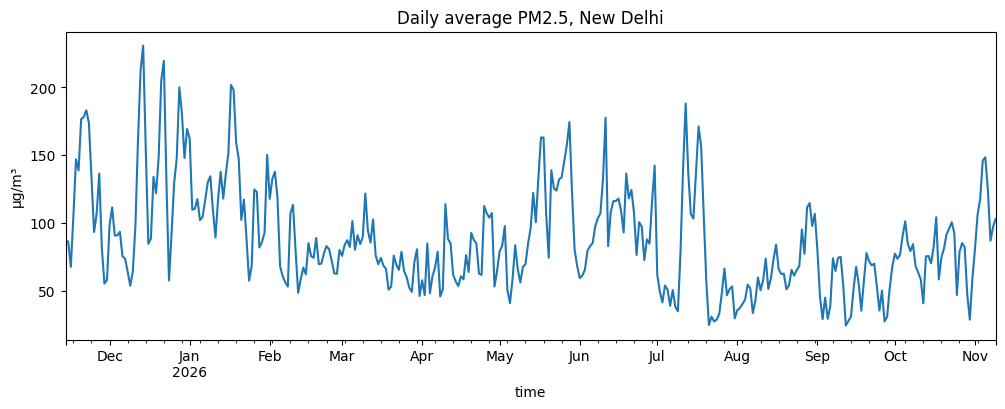

In [2]:
import matplotlib.pyplot as plt
df.set_index("time")["pm2_5"].resample("D").mean().plot(figsize=(12,4), title="Daily average PM2.5, New Delhi")
plt.ylabel("µg/m³"); plt.show()

In [3]:
df.to_csv("delhi_pm25_weather_hourly.csv", index=False)